# 03 — Evaluation

**Objective.** Score the four conditions with the same rules, compare them question by question, and explain *why* answers fail: retrieval, representation, visual reading, reasoning, citation, abstention or annotation. This notebook makes **no API call**; it reads saved predictions.

| | |
|---|---|
| **Input** | `predictions/{A,B,C,D}.jsonl` and `manifest.json` (02); `questions.parquet`, `pages.parquet`, page images (00); `retrieval_summary.csv` (01); frozen result files as regression references |
| **Output** | tables and figures below; `data/processed/mmlongbench_doc/evaluation_summary.json` |

## Method

**Scoring** re-implements the rule-based stage of MMLongBench-Doc `eval/eval_score.py` (commit `d73f0dc`), using the **reference** `answer_format`:

| `answer_format` | rule |
|---|---|
| `Int` | exact equality after `int(float(prediction))` |
| `Float` | equal within 1 % relative tolerance, also accepting ×100 or ÷100 (percentage vs fraction) |
| `Str`, `None` | lower-case; strip parenthesised text, quotes, `$`, `%`. Exact match for URLs, dates, phone-like numbers, e-mails, file names; otherwise ANLS with threshold 0.5 |
| `List` | same length required; elements cleaned and sorted; exact join for numeric items, otherwise the **minimum** ANLS over pairs |

$$\text{ANLS}(g, p) = 1 - \frac{\text{Lev}(g,p)}{\max(|g|,|p|)} \ \text{ if this exceeds } 0.5, \text{ else } 0.$$

Deviations from the official code: `ast.literal_eval` instead of `eval` for list strings, and a malformed list string is treated as one string. Kept on purpose: the official `get_clean_string` tries to strip `mile`/`million` suffixes but discards the result, so those suffixes stay. Parity was checked against hand-traced cases, not by running the official file.

**Aggregates** (official definitions). *Accuracy* = mean score. *F1*: recall = answerable score / answerable questions, precision = answerable score / predictions that are not `"Not answerable"`, so F1 penalises missed answers and invented answers to unanswerable questions. A question is **correct** when its score is above 0 (ANLS scores are 0 or above 0.5).

**Citations.** *Validity*: every cited page was supplied. *Correctness*: at least one cited page is annotated evidence (answerable questions).

**Paired comparisons.** Each question is answered under both conditions of a comparison, so it is its own control. Reported: fixed / broken counts and the exact McNemar test on the discordant pairs,
$$p = \min\!\left(1,\ 2 \sum_{i=0}^{\min(f, r)} \binom{f + r}{i} 2^{-(f+r)}\right).$$
McNemar assumes independent questions, but here they are **clustered in 6 documents**, so the p-values are optimistic; the number of documents that improve or worsen is the honest unit.

In [1]:
from collections import Counter
from math import comb, isclose
from pathlib import Path
import ast
import json
import re
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf
from IPython.display import Markdown, display

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 170)


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find the repository root")


PROJECT_ROOT = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "mmlongbench_doc"
PREDICTIONS_DIR = PROCESSED_DIR / "predictions"
TESSDATA_DIR = PROJECT_ROOT / "resources" / "tessdata"
FROZEN_TEXT_RUN = PROJECT_ROOT / "experiments" / "frozen" / "mmlongbench_doc" / "text_run_20261119T220858Z_a351a532"
FROZEN_IMAGE_RUN = PROJECT_ROOT / "experiments" / "frozen" / "mmlongbench_doc" / "image_run_20261119T232847Z_65ccf1ef"
PRICES = {"input": 0.15, "output": 0.60}  # assumed USD per 1M tokens for gpt-4o-mini, as in 02

for path in [PROCESSED_DIR / "questions.parquet", PROCESSED_DIR / "pages.parquet", PROCESSED_DIR / "retrieval_summary.csv", PREDICTIONS_DIR / "manifest.json"]:
    assert path.is_file(), f"{path.name} is missing: run notebooks 00, 01 and 02 first"


def read_jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]


questions = pd.read_parquet(PROCESSED_DIR / "questions.parquet")
questions["evidence_pages"] = questions["evidence_pages"].map(lambda values: [int(v) for v in values])
questions["evidence_sources"] = questions["evidence_sources"].map(list)
subset = questions[questions["in_subset"]].reset_index(drop=True)
VISUAL_SOURCES = {"Chart", "Figure"}
subset["evidence_group"] = np.where(~subset["answerable"], "unanswerable",
                                    np.where(subset["evidence_sources"].map(lambda s: bool(VISUAL_SOURCES & set(s))), "chart or figure", "text, layout or table only"))
reference = subset.set_index("qid")
pages = pd.read_parquet(PROCESSED_DIR / "pages.parquet")
page_lookup = pages.set_index(["doc_id", "page"])
image_manifest = pd.read_csv(PROCESSED_DIR / "render_manifest.csv").set_index(["doc_id", "page"])

prediction_manifest = json.loads((PREDICTIONS_DIR / "manifest.json").read_text())
records = {name: read_jsonl(PREDICTIONS_DIR / f"{name}.jsonl") for name in "ABCD"}
LABELS = {name: info["label"] for name, info in prediction_manifest["conditions"].items()}
print(f"Predictions written in mode {prediction_manifest['mode']!r} at {prediction_manifest['written_at']} (model {prediction_manifest['model']}):")
pd.DataFrame(prediction_manifest["conditions"]).T[["label", "records", "status", "source"]]

Predictions written in mode 'replay' at 2026-11-20T15:03:10+00:00 (model gpt-4o-mini-2024-07-18):


,label,records,status,source
A,"A. text, retrieved",57,replayed: {'ok': 57},experiments/frozen/mmlongbench_doc/text_run_20261119T220...
B,"B. images, retrieved",57,replayed: {'ok': 57},experiments/frozen/mmlongbench_doc/image_run_20261119T23...
C,"C. text, oracle",40,replayed: {'ok': 40},experiments/frozen/mmlongbench_doc/text_run_20261119T220...
D,"D. images, oracle",40,"replayed: {'ok': 38, 'skipped_context_limit': 2}",experiments/frozen/mmlongbench_doc/image_run_20261119T23...


## 1. Scoring rules, validated before use

In [2]:
def levenshtein_distance(s1, s2):
    if len(s1) > len(s2):
        s1, s2 = s2, s1
    distances = range(len(s1) + 1)
    for i2, c2 in enumerate(s2):
        new_distances = [i2 + 1]
        for i1, c1 in enumerate(s1):
            new_distances.append(distances[i1] if c1 == c2 else 1 + min(distances[i1], distances[i1 + 1], new_distances[-1]))
        distances = new_distances
    return distances[-1]


def anls_compute(groundtruth, prediction, threshold=0.5):
    length = max(len(groundtruth.upper()), len(prediction.upper()))
    anls = 1.0 - (0.0 if length == 0 else levenshtein_distance(groundtruth, prediction) / length)
    return 0.0 if anls <= threshold else anls


def is_float_equal(reference, prediction, include_percentage=False, is_close=False):
    def get_precision(value):
        text = str(value)
        return len(text.split(".")[-1]) if "." in text else 3

    reference = float(str(reference).strip().rstrip("%").strip())
    try:
        prediction = float(str(prediction).strip().rstrip("%").strip())
    except (TypeError, ValueError):
        return False
    for item in ([reference / 100, reference, reference * 100] if include_percentage else [reference]):
        if is_close and isclose(item, prediction, rel_tol=0.01):
            return True
        precision = max(min(get_precision(prediction), get_precision(item)), 2)
        if round(prediction, precision) == round(item, precision):
            return True
    return False


def get_clean_string(s):
    s = str(s).lower().strip()
    # Official quirk kept: the code calls s.rstrip("mile") etc. without assigning the result, so unit suffixes stay.
    s = re.sub(r"\s*\([^)]*\)", "", s).strip()  # remove parenthesised text
    s = re.sub(r"^['\"]|['\"]$", "", s).strip()  # remove surrounding quotes
    s = s.strip().lstrip("$").strip()
    return s.strip().rstrip("%").strip()


EXACT_MATCH_PATTERNS = [
    r"\b\d+(-\d+|\s\d+)?\b",  # phone-like numbers
    r"\b\d{4}[-\s]\d{2}[-\s]\d{2}\b",  # YYYY-MM-DD
    r"\b\d{4}[-\s]\d{2}\b",  # YYYY-MM
    r"[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}",  # e-mail address
]


def is_exact_match(s):
    return ("https://" in s or s.endswith(".py") or s.endswith("ipynb") or s.startswith("page") or "a.m." in s or "p.m." in s
            or any(re.fullmatch(pattern, s) for pattern in EXACT_MATCH_PATTERNS))


def isfloat(value):
    try:
        float(value)
        return True
    except (TypeError, ValueError):
        return False


def as_list(value):
    if isinstance(value, str) and value.startswith("["):
        try:
            value = ast.literal_eval(value)
        except (ValueError, SyntaxError):
            pass  # deviation: the official eval() would raise here
    return value if isinstance(value, list) else [value]


def eval_score(gt, pred, answer_type):
    if answer_type == "Int":
        try:
            gt, pred = int(gt), int(float(pred))
        except Exception:  # the official code uses a bare except
            pred = ""
        score = gt == pred
    elif answer_type == "Float":
        try:
            gt, pred = float(get_clean_string(str(gt))), float(get_clean_string(str(pred)))
        except Exception:
            pred = ""
        score = is_float_equal(gt, pred, include_percentage=True, is_close=True)
    elif answer_type in ("Str", "None"):
        gt, pred = get_clean_string(gt), get_clean_string(pred)
        score = gt == pred if is_exact_match(gt) else anls_compute(gt, pred)
    else:  # List
        gt, pred = as_list(gt), as_list(pred)
        if len(gt) != len(pred):
            score = 0.0
        else:
            gt, pred = sorted(get_clean_string(i) for i in gt), sorted(get_clean_string(i) for i in pred)
            score = "-".join(gt) == "-".join(pred) if isfloat(gt[0]) or is_exact_match(gt[0]) else min(anls_compute(g, p) for g, p in zip(gt, pred))
    return float(score)


def accuracy_and_f1(scored):
    accuracy = scored["score"].mean()
    answerable, predicted_answer = scored["answer"] != "Not answerable", scored["pred"] != "Not answerable"
    if answerable.sum() == 0 or predicted_answer.sum() == 0:
        return accuracy, 0.0  # the official code catches this ZeroDivisionError and returns F1 = 0
    recall = scored.loc[answerable, "score"].sum() / answerable.sum()
    precision = scored.loc[answerable, "score"].sum() / predicted_answer.sum()
    return accuracy, (2 * recall * precision / (recall + precision) if recall + precision > 0 else 0.0)

Each case targets one branch of the rules. `expected` was traced by hand from the official source; a mismatch would mean a transcription error or a wrong trace.

In [3]:
SCORING_CASES = [  # reference, prediction, format, expected, what it checks
    ("Less well-off", "less well off", "Str", 1 - 1 / 13, "ANLS partial credit: 1 edit / 13 chars"),
    ("Pew Research Center", "Pew Research Centre", "Str", 1 - 2 / 19, "ANLS: transposition costs 2 edits"),
    ("Latinos", "Asian Americans", "Str", 0.0, "ANLS <= 0.5 is set to 0"),
    ("Not answerable", "Not answerable", "None", 1.0, "correct abstention"),
    ("Not answerable", "The report does not say", "None", 0.0, "abstention must use the exact phrase"),
    ("12", "12.0", "Int", 1.0, "Int: int(float(pred))"),
    ("12", "twelve", "Int", 0.0, "Int: unparseable prediction scores 0"),
    ("18.29%", "18.3", "Float", 1.0, "Float: 1% relative tolerance"),
    ("0.1", "10%", "Float", 1.0, "Float: fraction vs percentage (x100)"),
    ("51%", "49", "Float", 0.0, "Float: outside tolerance"),
    ("['Circle', 'Rectangle']", "['rectangle', 'circle']", "List", 1.0, "List: order and case ignored"),
    ("['White', '10%']", "['White']", "List", 0.0, "List: length mismatch scores 0"),
    ("['2014', '2016']", "['2016', '2014']", "List", 1.0, "List: numeric items use exact join"),
    ("https://www.example.com", "www.example.com", "Str", 0.0, "URL requires exact match"),
    ("2016-06", "2016-06", "Str", 1.0, "YYYY-MM requires exact match"),
    ("$1,200 (approx.)", "1,200", "Str", 1.0, "cleaning drops $ and parenthesised text"),
    ("5 miles", "5", "Str", 0.0, "official quirk: 'miles' is not stripped"),
]
cases = pd.DataFrame(SCORING_CASES, columns=["reference", "prediction", "format", "expected", "checks"])
cases["local"] = [eval_score(r, p, f) for r, p, f in zip(cases["reference"], cases["prediction"], cases["format"])]
assert all(isclose(a, b, abs_tol=1e-9) for a, b in zip(cases["local"], cases["expected"])), "a scoring rule differs from the hand trace"

# A reference answer should score 1.0 against itself; rows where it cannot are unanswerable under the official rules.
questions["self_score"] = [eval_score(r.answer, r.answer, r.answer_format) for r in questions.itertuples()]
unscorable = questions[questions["self_score"] < 1.0]
assert len(unscorable) == 4, "new unscorable references appeared"
toy = pd.DataFrame({"answer": ["A", "B", "Not answerable"], "pred": ["A", "Not answerable", "C"], "score": [1.0, 0.0, 0.0]})
assert all(isclose(x, y) for x, y in zip(accuracy_and_f1(toy), (1 / 3, 0.5)))  # 1 correct, 1 false abstention, 1 invented answer
display(cases[["reference", "prediction", "format", "checks", "local"]].round(4))
print(f"{len(cases)} rule checks and the F1 toy check passed. References that cannot score 1.0 against themselves: {len(unscorable)} of {len(questions)}; "
      f"in the subset: {unscorable.loc[unscorable['in_subset'], 'qid'].tolist()}")

,reference,prediction,format,checks,local
0,Less well-off,less well off,Str,ANLS partial credit: 1 edit / 13 chars,0.9231
1,Pew Research Center,Pew Research Centre,Str,ANLS: transposition costs 2 edits,0.8947
2,Latinos,Asian Americans,Str,ANLS <= 0.5 is set to 0,0.0000
3,Not answerable,Not answerable,None,correct abstention,1.0000
4,Not answerable,The report does not say,None,abstention must use the exact phrase,0.0000
5,12,12.0,Int,Int: int(float(pred)),1.0000
6,12,twelve,Int,Int: unparseable prediction scores 0,0.0000
7,18.29%,18.3,Float,Float: 1% relative tolerance,1.0000
8,0.1,10%,Float,Float: fraction vs percentage (x100),1.0000
9,51%,49,Float,Float: outside tolerance,0.0000


17 rule checks and the F1 toy check passed. References that cannot score 1.0 against themselves: 4 of 1091; in the subset: ['mmlb-0733', 'mmlb-0735']


## 2. Score the four conditions

A metric covers exactly the questions that received a reply. D's two context-limit skips leave its denominator by protocol, so C is also reported on the same 38 questions.

In [4]:
def score_condition(records_list):
    frame = subset.merge(pd.DataFrame(records_list), on="qid", how="inner", validate="one_to_one")
    frame = frame[frame["status"].isin(["ok", "parse_error"])].copy()
    frame["score"] = [eval_score(r.answer, r.pred, r.answer_format) for r in frame.itertuples()]
    frame["correct"] = frame["score"] > 0
    frame["citations_valid"] = [set(c) <= set(s) for c, s in zip(frame["cited_pages"], frame["supplied_pages"])]
    frame["evidence_supplied"] = [bool(set(e) & set(s)) if a else np.nan for e, s, a in zip(frame["evidence_pages"], frame["supplied_pages"], frame["answerable"])]
    frame["cites_evidence"] = [bool(set(c) & set(e)) if a else np.nan for c, e, a in zip(frame["cited_pages"], frame["evidence_pages"], frame["answerable"])]
    frame["predicted_unanswerable"] = frame["pred"].map(lambda p: isinstance(p, str) and p == "Not answerable")
    return frame


def condition_metrics(frame):
    answerable, unanswerable = frame[frame["answerable"]], frame[~frame["answerable"]]
    accuracy, f1 = accuracy_and_f1(frame)
    return {
        "questions (answerable / unanswerable)": f"{len(answerable)} / {len(unanswerable)}",
        "correct answerable": f"{int(answerable['correct'].sum())} / {len(answerable)}",
        "accuracy on answerable": answerable["score"].mean(),
        "accuracy, all questions": accuracy,
        "F1 (official definition)": f1 if len(unanswerable) else np.nan,
        "correct abstention (unanswerable)": unanswerable["score"].mean() if len(unanswerable) else np.nan,
        "false abstention (answerable)": answerable["predicted_unanswerable"].mean(),
        "citation validity": frame["citations_valid"].mean(),
        "cites an evidence page (answerable)": answerable["cites_evidence"].astype(float).mean(),
        "unparseable replies": int((frame["status"] == "parse_error").sum()),
    }


scored = {name: score_condition(records[name]) for name in "ABCD"}
scored["C38"] = scored["C"][scored["C"]["qid"].isin(scored["D"]["qid"])]
TABLE = {"A": LABELS["A"], "B": LABELS["B"], "C": LABELS["C"] + " (40)", "C38": LABELS["C"] + " (38)", "D": LABELS["D"] + " (38)"}
metrics_table = pd.DataFrame({TABLE[n]: condition_metrics(scored[n]) for n in TABLE})
metrics_table.map(lambda v: round(v, 3) if isinstance(v, float) else v)

,"A. text, retrieved","B. images, retrieved","C. text, oracle (40)","C. text, oracle (38)","D. images, oracle (38)"
questions (answerable / unanswerable),40 / 17,40 / 17,40 / 0,38 / 0,38 / 0
correct answerable,7 / 40,7 / 40,9 / 40,9 / 38,11 / 38
accuracy on answerable,0.175,0.175,0.225,0.237,0.289
"accuracy, all questions",0.263,0.228,0.225,0.237,0.289
F1 (official definition),0.165,0.156,NaN,NaN,NaN
correct abstention (unanswerable),0.471,0.353,NaN,NaN,NaN
false abstention (answerable),0.1,0.025,0.075,0.079,0.026
citation validity,1.0,0.895,1.0,1.0,0.921
cites an evidence page (answerable),0.65,0.6,0.875,0.895,0.789
unparseable replies,0,0,0,0,0


In [5]:
# Regression against the frozen result files: every per-question score and the headline counts.
frozen_scores = {
    "A": pd.read_csv(FROZEN_TEXT_RUN / "scored_predictions.csv").set_index("qid")["score"],
    "C": pd.read_csv(FROZEN_TEXT_RUN / "oracle_paired.csv").set_index("qid")["oracle_score"],
    "B": pd.read_csv(FROZEN_IMAGE_RUN / "scored_b_images_retrieved.csv").set_index("qid")["score"],
    "D": pd.read_csv(FROZEN_IMAGE_RUN / "scored_d_images_oracle.csv").set_index("qid")["score"],
}
if prediction_manifest["mode"] == "replay":
    for name, saved in frozen_scores.items():
        now = scored[name].set_index("qid")["score"]
        assert set(now.index) == set(saved.index) and np.allclose(now.loc[saved.index], saved, atol=1e-12), name
    counts = {n: (int(scored[n].loc[scored[n]["answerable"], "correct"].sum()), int(scored[n]["answerable"].sum())) for n in ("A", "B", "C", "C38", "D")}
    assert counts == {"A": (7, 40), "B": (7, 40), "C": (9, 40), "C38": (9, 38), "D": (11, 38)}, counts
    frozen_metrics = json.loads((FROZEN_IMAGE_RUN / "summary.json").read_text())["metrics"]
    for name, key in (("A", "A. text, retrieved"), ("B", "B. images, retrieved")):
        accuracy, f1 = accuracy_and_f1(scored[name])
        assert isclose(accuracy, frozen_metrics[key]["accuracy (all questions)"]) and isclose(f1, frozen_metrics[key]["F1 (official definition)"])
    print("Regression passed: all per-question scores equal the frozen files; answerable correct A 7/40, B 7/40, C 9/40 (9/38), D 11/38; "
          "accuracy and F1 for A and B equal the frozen summary.")
else:
    print("Predictions are not the frozen replay: regression against the frozen results is not applicable.")

Regression passed: all per-question scores equal the frozen files; answerable correct A 7/40, B 7/40, C 9/40 (9/38), D 11/38; accuracy and F1 for A and B equal the frozen summary.


## 3. Retrieval versus reading: where the errors sit

Retrieval quality comes from 01. Combining it with the answers separates "the evidence was not supplied" from "the evidence was supplied and misread". The groups are defined by how much evidence BM25 put in its top 5.

In [6]:
retrieval_summary = pd.read_csv(PROCESSED_DIR / "retrieval_summary.csv", index_col="k")
print("Retrieval (01): BM25 Recall@5 {:.3f}, Hit@5 {:.3f} on 40 answerable questions.".format(
    retrieval_summary.loc[5, "BM25 Recall@k"], retrieval_summary.loc[5, "BM25 Hit@k"]))

retrieved = {r["qid"]: r["supplied_pages"] for r in records["A"]}
recall5 = {q: len(set(reference.loc[q, "evidence_pages"]) & set(retrieved[q])) / len(set(reference.loc[q, "evidence_pages"]))
           for q in subset.loc[subset["answerable"], "qid"]}
GROUPS = ["all evidence in top 5", "some evidence in top 5", "no evidence in top 5"]
retrieval_group = {q: GROUPS[0] if r == 1 else GROUPS[1] if r > 0 else GROUPS[2] for q, r in recall5.items()}
for frame in scored.values():
    frame["retrieval_group"] = frame["qid"].map(retrieval_group).fillna("unanswerable")

by_group = pd.DataFrame({TABLE[n]: scored[n][scored[n]["answerable"]].groupby("retrieval_group")["score"].mean() for n in ("A", "B", "C", "D")}).reindex(GROUPS)
by_group.insert(0, "questions", pd.Series(retrieval_group).value_counts().reindex(GROUPS))
display(by_group.round(3))

for reader, (retrieved_name, oracle_name) in {"text": ("A", "C38"), "images": ("B", "D")}.items():
    same = scored[retrieved_name][scored[retrieved_name]["qid"].isin(scored["D"]["qid"])]
    acc_r, acc_o = same["score"].mean(), scored[oracle_name]["score"].mean()
    print(f"{reader:>6} reader, 38 questions: error {1 - acc_r:.3f} = fixed by supplying the evidence {acc_o - acc_r:+.3f} "
          f"+ remaining with the evidence in context {1 - acc_o:.3f}")

Retrieval (01): BM25 Recall@5 0.689, Hit@5 0.800 on 40 answerable questions.


,questions,"A. text, retrieved","B. images, retrieved","C. text, oracle (40)","D. images, oracle (38)"
retrieval_group,,,,,
all evidence in top 5,24,0.250,0.292,0.250,0.292
some evidence in top 5,8,0.000,0.000,0.125,0.000
no evidence in top 5,8,0.125,0.000,0.250,0.571


  text reader, 38 questions: error 0.816 = fixed by supplying the evidence +0.053 + remaining with the evidence in context 0.763
images reader, 38 questions: error 0.816 = fixed by supplying the evidence +0.105 + remaining with the evidence in context 0.711


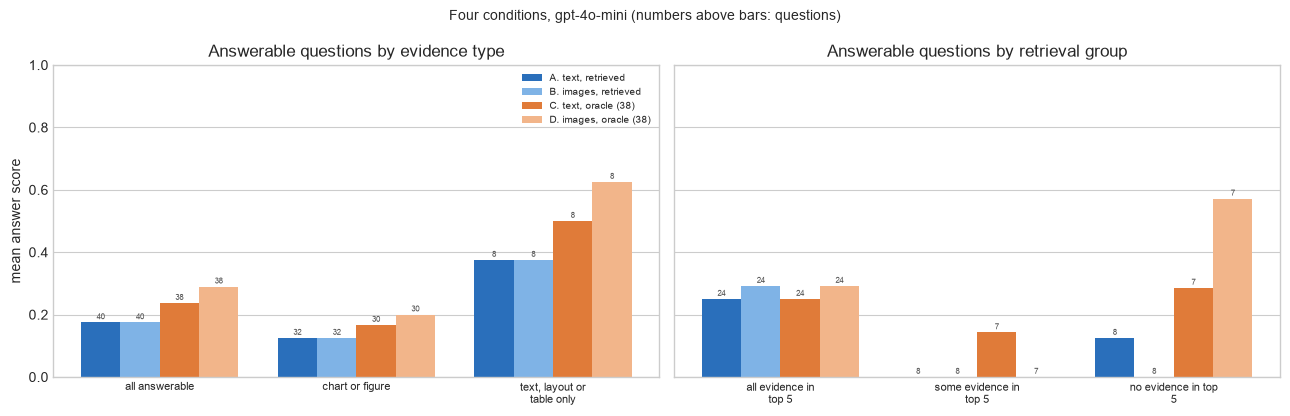

In [7]:
colors = {"A": "#2A6FBB", "B": "#7FB3E6", "C": "#E07B39", "D": "#F2B58A"}
panels = {"evidence type": ["all answerable", "chart or figure", "text, layout or table only"], "retrieval group": GROUPS}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, (panel, groups) in zip(axes, panels.items()):
    x = np.arange(len(groups))
    for i, name in enumerate("ABCD"):
        frame = scored["C38" if name == "C" else name]
        frame = frame[frame["answerable"]]
        selected = [frame if g == "all answerable" else frame[frame["evidence_group" if panel == "evidence type" else "retrieval_group"] == g] for g in groups]
        bars = ax.bar(x - 0.3 + 0.2 * i, [s["score"].mean() if len(s) else np.nan for s in selected], width=0.2, color=colors[name],
                      label=LABELS[name] + (" (38)" if name in "CD" else ""))
        for bar, s in zip(bars, selected):
            ax.annotate(f"{len(s)}", (bar.get_x() + bar.get_width() / 2, np.nan_to_num(bar.get_height()) + 0.01), ha="center", fontsize=6, color="#555555")
    ax.set_xticks(x, [textwrap.fill(g, 18) for g in groups], fontsize=8)
    ax.set(title=f"Answerable questions by {panel}", ylim=(0, 1))
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("mean answer score")
axes[0].legend(fontsize=7, loc="upper right")
fig.suptitle("Four conditions, gpt-4o-mini (numbers above bars: questions)", fontsize=10)
plt.tight_layout()
plt.show()

- **Text: reading is the bottleneck, not retrieval.** Supplying the evidence fixes only 2 text answers (0.184 → 0.237 on 38 questions); 0.763 of the error remains with the evidence in context.
- **Images benefit more from correct pages:** 4 fixed, 0 broken (0.184 → 0.289). All 4 image fixes are questions with **no** evidence in the BM25 top 5: once the image reader receives the page, it reads it.
- Chart and figure questions stay hard in every condition. Group sizes are 4–30 questions, so the bars show where errors sit, not precise estimates.

## 4. Image legibility per document

Resolution is a candidate cause of image failures. Tesseract OCR of the **exact image sent to the model** measures the share of the words of the text the text condition received for the same page. Three pages per document are sampled, evenly spaced among the pages B and D received. Tesseract is not gpt-4o-mini, so this is a pessimistic **proxy**, but it is a measurement.

In [8]:
WORD_PATTERN = re.compile(r"[a-z]{4,}")


def recovered_fraction(ocr_text, reference_text):
    reference_words = set(WORD_PATTERN.findall(str(reference_text).lower()))
    return len(set(WORD_PATTERN.findall(ocr_text.lower())) & reference_words) / len(reference_words) if reference_words else np.nan


def model_png(doc_id, page_number):
    return (PROJECT_ROOT / image_manifest.loc[(doc_id, page_number), "image_path"]).read_bytes()


def ocr_png(png):
    with pymupdf.open("pdf", pymupdf.Pixmap(png).pdfocr_tobytes(language="eng", tessdata=str(TESSDATA_DIR))) as ocr_pdf:
        return ocr_pdf[0].get_text()


image_pages = pd.DataFrame(sorted({(reference.loc[r["qid"], "doc_id"], p) for n in "BD" for r in records[n] for p in r["supplied_pages"]}), columns=["doc_id", "page"])
sample = pd.concat([g.iloc[np.unique(np.linspace(0, len(g) - 1, 3).round().astype(int))] for _, g in image_pages.groupby("doc_id")])
sample["text source"] = ["OCR 150 dpi" if page_lookup.loc[(d, p), "ocr_used"] else "native" for d, p in zip(sample["doc_id"], sample["page"])]
sample["recovered"] = [recovered_fraction(ocr_png(model_png(d, p)), page_lookup.loc[(d, p), "text"]) for d, p in zip(sample["doc_id"], sample["page"])]
legibility = sample.groupby("doc_id")["recovered"].median().rename("legibility (OCR proxy)")
legibility_table = legibility.to_frame().assign(**{"image px": [f"{image_manifest.loc[(d, 1), 'width_px']} × {image_manifest.loc[(d, 1), 'height_px']}" for d in legibility.index]})
legibility_table.round(2)

,legibility (OCR proxy),image px
doc_id,,
2210.02442v1.pdf,0.05,512 × 663
PG_2020.05.21_International-Cooperation-COVID_FINAL.pdf,0.40,512 × 663
bdf54dxa.pdf,0.06,512 × 663
earlybird-110722143746-phpapp02_95.pdf,0.96,683 × 512
germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95.pdf,0.83,911 × 512
watch_d.pdf,0.92,512 × 725


The slide decks and the watch manual remain legible at model resolution (0.83–0.96), the PG report is middling (0.40), and the academic paper and the guidebook `bdf54dxa` (text drawn as vector outlines, see 00) are nearly illegible to OCR (0.05, 0.06), while the text conditions read them from native text or 150-dpi OCR. A loss of image accuracy on those two documents is a **resolution effect**, not evidence that images are worse in general.

## 5. Paired comparisons

Every comparison merges two scored conditions **on `qid`** (inner join, one-to-one), so each row is one question under both conditions. Comparison 0 (text, retrieved → oracle) validates the code: it must reproduce 2 fixed (`mmlb-0359`, `mmlb-0740`) and 0 broken.

In [9]:
PAIR_KEYS = ["qid", "doc_id", "answerable", "evidence_group", "retrieval_group", "answer", "answer_format", "evidence_pages"]
PAIR_VALUES = ["pred", "score", "correct", "cited_pages", "supplied_pages", "evidence_supplied", "predicted_unanswerable", "citations_valid", "cites_evidence"]


def paired_frame(a, b):
    left = a[PAIR_KEYS + PAIR_VALUES].rename(columns={c: f"{c}_a" for c in PAIR_VALUES})
    right = b[["qid"] + PAIR_VALUES].rename(columns={c: f"{c}_b" for c in PAIR_VALUES})
    paired = left.merge(right, on="qid", how="inner", validate="one_to_one")
    paired["score_diff"] = paired["score_b"] - paired["score_a"]
    a_ok, b_ok = paired["correct_a"].astype(bool), paired["correct_b"].astype(bool)
    paired["transition"] = np.select([~a_ok & b_ok, a_ok & ~b_ok, a_ok & b_ok], ["fixed", "broken", "both correct"], "both wrong")
    return paired


def mcnemar_exact_p(fixed, broken):
    n = fixed + broken
    return 1.0 if n == 0 else min(1.0, 2 * sum(comb(n, i) for i in range(min(fixed, broken) + 1)) / 2**n)


assert mcnemar_exact_p(0, 0) == 1.0 and mcnemar_exact_p(2, 0) == 0.5 and isclose(mcnemar_exact_p(5, 1), 2 * 7 / 64)


def paired_summary(paired):
    t = paired["transition"].value_counts()
    fixed, broken = int(t.get("fixed", 0)), int(t.get("broken", 0))
    per_document = paired.groupby("doc_id")["score_diff"].mean()
    return {
        "questions / documents": f"{len(paired)} / {paired['doc_id'].nunique()}",
        "accuracy A": paired["score_a"].mean(), "accuracy B": paired["score_b"].mean(),
        "difference B − A": paired["score_b"].mean() - paired["score_a"].mean(),
        "fixed (A wrong → B right)": fixed, "broken (A right → B wrong)": broken,
        "both correct / both wrong": f"{int(t.get('both correct', 0))} / {int(t.get('both wrong', 0))}",
        "exact McNemar p (ignores clustering)": mcnemar_exact_p(fixed, broken),
        "documents better / worse / equal": f"{int((per_document > 0).sum())} / {int((per_document < 0).sum())} / {int((per_document == 0).sum())}",
    }


A, B, C, D = (scored[n] for n in "ABCD")
answerable = lambda frame: frame[frame["answerable"]]
COMPARISONS = {
    "0. reference — text: retrieved → oracle": (answerable(A), C),
    "1. retrieved pages: text → images (answerable)": (answerable(A), answerable(B)),
    "1b. retrieved pages: text → images (all questions)": (A, B),
    "2. oracle pages: text → images": (scored["C38"], D),
    "3. images: retrieved → oracle": (B[B["qid"].isin(D["qid"])], D),
}
PAIRED = {name: paired_frame(a, b) for name, (a, b) in COMPARISONS.items()}
paired_table = pd.DataFrame({name: paired_summary(p) for name, p in PAIRED.items()})
assert set(PAIRED["0. reference — text: retrieved → oracle"].query("transition == 'fixed'")["qid"]) == {"mmlb-0359", "mmlb-0740"}
if prediction_manifest["mode"] == "replay":  # regression against the frozen paired summary
    frozen_paired = json.loads((FROZEN_IMAGE_RUN / "summary.json").read_text())["paired"]
    for name, summary in paired_table.items():
        for key, value in summary.items():
            assert (isclose(value, frozen_paired[name][key]) if isinstance(value, float) else value == frozen_paired[name][key]), (name, key)
    print("Paired summaries identical to the frozen run.")
paired_table.map(lambda v: round(v, 3) if isinstance(v, float) else v)

Paired summaries identical to the frozen run.


,0. reference — text: retrieved → oracle,1. retrieved pages: text → images (answerable),1b. retrieved pages: text → images (all questions),2. oracle pages: text → images,3. images: retrieved → oracle
questions / documents,40 / 6,40 / 6,57 / 6,38 / 6,38 / 6
accuracy A,0.175,0.175,0.263,0.237,0.184
accuracy B,0.225,0.175,0.228,0.289,0.289
difference B − A,0.05,0.0,-0.035,0.053,0.105
fixed (A wrong → B right),2,3,3,6,4
broken (A right → B wrong),0,3,5,4,0
both correct / both wrong,7 / 31,4 / 30,10 / 39,5 / 23,7 / 27
exact McNemar p (ignores clustering),0.5,1.0,0.727,0.754,0.125
documents better / worse / equal,2 / 0 / 4,1 / 3 / 2,1 / 4 / 1,2 / 3 / 1,2 / 0 / 4


In [10]:
def subgroup_table(paired, by):
    table = paired.groupby(by).agg(questions=("qid", "size"), accuracy_A=("score_a", "mean"), accuracy_B=("score_b", "mean"),
                                   fixed=("transition", lambda t: int((t == "fixed").sum())), broken=("transition", lambda t: int((t == "broken").sum())))
    table["difference"] = table["accuracy_B"] - table["accuracy_A"]
    return table.round(3)


for name in ("1. retrieved pages: text → images (answerable)", "2. oracle pages: text → images"):
    display(Markdown(f"**{name}** — subgroups (exploratory: small n, clustered in documents)"))
    by_document = subgroup_table(PAIRED[name], "doc_id")
    by_document.insert(0, "legibility", by_document.index.map(legibility).round(2))
    display(by_document.rename(index=lambda d: d[:30]))
    display(subgroup_table(PAIRED[name], "evidence_group"))

primary = PAIRED["1. retrieved pages: text → images (answerable)"]
print("Comparison 1, the questions that changed:")
primary.loc[primary["transition"].isin(["fixed", "broken"]), ["qid", "doc_id", "evidence_group", "answer", "pred_a", "pred_b", "transition"]].assign(doc_id=lambda f: f["doc_id"].str[:14])

**1. retrieved pages: text → images (answerable)** — subgroups (exploratory: small n, clustered in documents)

,legibility,questions,accuracy_A,accuracy_B,fixed,broken,difference
doc_id,,,,,,,
2210.02442v1.pdf,0.05,6,0.000,0.000,0,0,0.000
PG_2020.05.21_International-Co,0.40,7,0.286,0.286,0,0,0.000
bdf54dxa.pdf,0.06,5,0.200,0.000,0,1,-0.200
earlybird-110722143746-phpapp0,0.96,7,0.143,0.000,0,1,-0.143
germanwingsdigitalcrisisanalys,0.83,11,0.091,0.364,3,0,0.273
watch_d.pdf,0.92,4,0.500,0.250,0,1,-0.250


,questions,accuracy_A,accuracy_B,fixed,broken,difference
evidence_group,,,,,,
chart or figure,32,0.125,0.125,2,2,0.0
"text, layout or table only",8,0.375,0.375,1,1,0.0


**2. oracle pages: text → images** — subgroups (exploratory: small n, clustered in documents)

,legibility,questions,accuracy_A,accuracy_B,fixed,broken,difference
doc_id,,,,,,,
2210.02442v1.pdf,0.05,6,0.000,0.000,0,0,0.000
PG_2020.05.21_International-Co,0.40,7,0.429,0.286,0,1,-0.143
bdf54dxa.pdf,0.06,5,0.200,0.000,0,1,-0.200
earlybird-110722143746-phpapp0,0.96,5,0.200,0.400,2,1,0.200
germanwingsdigitalcrisisanalys,0.83,11,0.182,0.545,4,0,0.364
watch_d.pdf,0.92,4,0.500,0.250,0,1,-0.250


,questions,accuracy_A,accuracy_B,fixed,broken,difference
evidence_group,,,,,,
chart or figure,30,0.167,0.200,4,3,0.033
"text, layout or table only",8,0.500,0.625,2,1,0.125


Comparison 1, the questions that changed:


,qid,doc_id,evidence_group,answer,pred_a,pred_b,transition
0,mmlb-0033,earlybird-1107,chart or figure,63,63,64,broken
9,mmlb-0096,watch_d.pdf,"text, layout or table only",2,2,1,broken
11,mmlb-0313,bdf54dxa.pdf,chart or figure,2,2,1,broken
24,mmlb-0729,germanwingsdig,"text, layout or table only",41,71,41,fixed
26,mmlb-0732,germanwingsdig,chart or figure,5,3,5,fixed
31,mmlb-0739,germanwingsdig,chart or figure,4,3,4,fixed


## 6. Citations

An invalid citation names a page that was not supplied. For image replies, a candidate explanation is that the model cites the page number **printed on the page** instead of the `[Page N]` tag; in the PG report and in `bdf54dxa` the printed number is the physical number minus one (verified by looking at the pages, not computed here). The table checks, mechanically, whether each invalid cited page is exactly one below a supplied page.

In [11]:
citation_table = pd.DataFrame({
    LABELS[n]: {
        "replies": len(scored[n]),
        "citation validity": scored[n]["citations_valid"].mean(),
        "cites an evidence page (answerable)": answerable(scored[n])["cites_evidence"].astype(float).mean(),
        "correct answer without citing evidence": int((answerable(scored[n])["correct"] & ~answerable(scored[n])["cites_evidence"].astype(bool)).sum()),
        "replies with an invalid citation": int((~scored[n]["citations_valid"]).sum()),
    } for n in "ABCD"})
display(citation_table.map(lambda v: round(v, 3) if isinstance(v, float) else v))

invalid = pd.concat([scored[n].assign(condition=n)[~scored[n]["citations_valid"]] for n in "ABCD"])
invalid["invalid pages"] = [sorted(set(c) - set(s)) for c, s in zip(invalid["cited_pages"], invalid["supplied_pages"])]
invalid["every invalid page = a supplied page − 1"] = [all(p + 1 in s for p in bad) for bad, s in zip(invalid["invalid pages"], invalid["supplied_pages"])]
invalid[["condition", "qid", "doc_id", "supplied_pages", "cited_pages", "invalid pages", "every invalid page = a supplied page − 1"]].assign(doc_id=lambda f: f["doc_id"].str[:14])

,"A. text, retrieved","B. images, retrieved","C. text, oracle","D. images, oracle"
replies,57.00,57.000,40.000,38.000
citation validity,1.00,0.895,1.000,0.921
cites an evidence page (answerable),0.65,0.600,0.875,0.789
correct answer without citing evidence,1.00,1.000,0.000,1.000
replies with an invalid citation,0.00,6.000,0.000,3.000


,condition,qid,doc_id,supplied_pages,cited_pages,invalid pages,every invalid page = a supplied page − 1
17,B,mmlb-0316,bdf54dxa.pdf,"[47, 33, 46, 49, 14]",[13],[13],True
18,B,mmlb-0317,bdf54dxa.pdf,"[12, 14, 46, 26, 44]",[13],[13],True
26,B,mmlb-0358,PG_2020.05.21_,"[9, 14, 5, 8, 15]",[7],[7],True
27,B,mmlb-0359,PG_2020.05.21_,"[7, 11, 14, 8, 5]","[7, 10, 13]","[10, 13]",True
30,B,mmlb-0362,PG_2020.05.21_,"[5, 16, 14, 6, 13]","[15, 5]",[15],True
49,B,mmlb-0763,2210.02442v1.p,"[2, 3, 1, 8, 7]","[2, 4, 8]",[4],False
13,D,mmlb-0317,bdf54dxa.pdf,"[12, 14, 46, 26, 15]",[13],[13],True
21,D,mmlb-0362,PG_2020.05.21_,"[5, 16, 14, 6, 12]","[15, 11]","[11, 15]",True
35,D,mmlb-0763,2210.02442v1.p,"[2, 3, 1, 8, 7]","[2, 4, 8]",[4],False


- Text replies never cite an unsupplied page; image replies do so 9 times (6 in B, 3 in D).
- In **7 of the 9** replies (9 of the 11 invalid page numbers) every invalid page is exactly one below a supplied page, consistent with the printed-page explanation. The two exceptions are the same academic-paper question (`mmlb-0763`, page 4 cited with pages 1–3, 7 and 8 supplied). The archived notebook 15 summarised this as "8 of 9"; the mechanical count here is 7 of 9.
- Because of this, "cites an evidence page" underestimates image grounding: a reply can point at the right page under the wrong number.

## 7. Abstention

On the 17 unanswerable questions the only correct reply is `"Not answerable"`; on answerable questions that reply is a false abstention.

In [12]:
abstention = pd.DataFrame({
    LABELS[n]: {
        "correct abstention (unanswerable)": f"{int(scored[n].loc[~scored[n]['answerable'], 'correct'].sum())} / {int((~scored[n]['answerable']).sum())}" if n in "AB" else "—",
        "false abstention (answerable)": f"{int(answerable(scored[n])['predicted_unanswerable'].sum())} / {len(answerable(scored[n]))}",
        "false abstention with evidence supplied": int((answerable(scored[n])["predicted_unanswerable"] & answerable(scored[n])["evidence_supplied"].astype(bool)).sum()),
    } for n in "ABCD"})
display(abstention)
both = PAIRED["1b. retrieved pages: text → images (all questions)"]
print("Unanswerable questions where text abstained but images answered:")
both[~both["answerable"] & both["correct_a"] & ~both["correct_b"]][["qid", "pred_a", "pred_b", "cited_pages_b"]]

,"A. text, retrieved","B. images, retrieved","C. text, oracle","D. images, oracle"
correct abstention (unanswerable),8 / 17,6 / 17,—,—
false abstention (answerable),4 / 40,1 / 40,3 / 40,1 / 38
false abstention with evidence supplied,4,1,3,1


Unanswerable questions where text abstained but images answered:


,qid,pred_a,pred_b,cited_pages_b
5,mmlb-0038,Not answerable,Deutsche Bank Private Equity,[19]
56,mmlb-0770,Not answerable,The map by pseudo-labels has a larger confidence variance.,[22]


## 8. Error categorization

Some failure types can be assigned **mechanically**; others need a person to look at the page and the reply.

| failure type | identified by | automatic? |
|---|---|---|
| retrieval failure | answerable, no evidence page among the supplied pages | yes |
| abstention error | `"Not answerable"` with evidence supplied, or an answer to an unanswerable question | yes |
| text-representation failure (candidate) | same pages: text wrong, image right; stronger when the reference string is absent from the received text | candidate |
| visual-reading failure (candidate) | same pages: text right, image wrong | candidate |
| reasoning, citation, annotation | evidence supplied and readable, interpretation wrong; or a scoring/annotation problem | manual review |

`answer_in_text` (non-list answers only): does the normalised reference string occur, as whole tokens, in the text the text condition received for the supplied evidence pages? "Absent" does not prove an OCR failure, because many answers are computed; "present" shows the text did carry the answer.

In [13]:
def normalize_text(text):
    return re.sub(r"\s+", " ", str(text).lower()).strip()


def answer_in_supplied_text(row):
    if not row.answerable or row.answer_format == "List":
        return np.nan
    text = " ".join(normalize_text(page_lookup.loc[(row.doc_id, p), "text"]) for p in row.supplied_pages if p in set(row.evidence_pages))
    pattern = re.compile(r"(?<![0-9a-z])" + re.escape(normalize_text(row.answer)) + r"(?![0-9a-z])")
    return bool(text) and bool(pattern.search(text))


def outcome_category(row):
    if not row.answerable:
        return "correct abstention" if row.correct else "answered an unanswerable question"
    if row.correct:
        return "correct"
    if not row.evidence_supplied:
        return "retrieval failure (no evidence page supplied)"
    return "false abstention (evidence supplied)" if row.predicted_unanswerable else "wrong answer (evidence supplied)"


for frame in scored.values():
    frame["outcome"] = [outcome_category(r) for r in frame.itertuples()]
    frame["answer_in_text"] = [answer_in_supplied_text(r) for r in frame.itertuples()]
display(pd.DataFrame({LABELS[n]: scored[n]["outcome"].value_counts() for n in "ABCD"}).fillna(0).astype(int))

text_wrong = A[A["outcome"].isin(["false abstention (evidence supplied)", "wrong answer (evidence supplied)"])]
print("Condition A, wrong with the evidence supplied — was the reference string in the text the model received?")
display(text_wrong.groupby(["evidence_group", text_wrong["answer_in_text"].map({True: "present", False: "absent"}).fillna("n/a (list)")]).size().rename("questions").to_frame())

in_text = A.set_index("qid")["answer_in_text"]


def diagnostic(row):
    if not row.evidence_supplied_a:
        return "retrieval failure (no evidence supplied to either)"
    if row.correct_a and row.correct_b:
        return "both correct"
    if not row.correct_a and row.correct_b:
        return "fixed by images; answer string was in the text" if in_text.get(row.qid) is True else "text-representation failure (candidate)"
    if row.correct_a and not row.correct_b:
        return "visual-reading failure (candidate)"
    return "both wrong with evidence: visual reading or reasoning (manual review)"


primary["diagnostic"] = [diagnostic(r) for r in primary.itertuples()]
pd.crosstab(primary["diagnostic"], primary["evidence_group"], margins=True)

,"A. text, retrieved","B. images, retrieved","C. text, oracle","D. images, oracle"
outcome,,,,
answered an unanswerable question,9,11,0,0
correct,7,7,9,11
correct abstention,8,6,0,0
false abstention (evidence supplied),4,1,3,1
retrieval failure (no evidence page supplied),7,8,0,0
wrong answer (evidence supplied),22,24,28,26


Condition A, wrong with the evidence supplied — was the reference string in the text the model received?


questions
evidence_group             answer_in_text           
chart or figure            absent                 13
                           n/a (list)              1
                           present                11
text, layout or table only absent                  1

evidence_group,chart or figure,"text, layout or table only",All
diagnostic,,,
both correct,2,2,4
both wrong with evidence: visual reading or reasoning (manual review),23,0,23
fixed by images; answer string was in the text,2,0,2
retrieval failure (no evidence supplied to either),4,4,8
text-representation failure (candidate),0,1,1
visual-reading failure (candidate),1,1,2
All,32,8,40


### Manual review

Labels were assigned after looking at the rendered evidence pages, the OCR text and every reply, in two passes: 10 cases on 2026-11-20 (9 queued questions and `mmlb-0313`, outside the queue) and the 19 remaining queued questions on 2026-11-21. The queue holds every comparison-1 question that is a candidate or needs review.

Each case has **one primary label**, the failure judged decisive; secondary contributing factors (a partial retrieval miss, small print, a questionable reference) are recorded only in the explanation and are not counted. The 29 cases were selected by the queue, so their label counts are not error rates for the benchmark.

In [14]:
MANUAL_REVIEW_CATEGORIES = ("retrieval", "text representation", "visual reading", "reasoning or aggregation", "citation", "abstention", "annotation or scoring issue")
# First pass, 2026-11-20: 9 queued questions and mmlb-0313 (outside the queue).
ORIGINAL_REVIEWS = {
    "mmlb-0355": ("reasoning or aggregation", "The 'Less' bar for Liberal (56 %) is legible in the 512 x 663 image, but both readers answered with the chart's headline instead of comparing the bars."),
    "mmlb-0731": ("visual reading", "The early Lufthansa logo (p.7) is a ~12-px yellow Twitter avatar in the 911 x 512 image; the model reported only the later logo (p.8) and merged the two periods."),
    "mmlb-0736": ("annotation or scoring issue", "The slide says 'Within the first 4 hours: Airbus.com incorporates a pop-up notification'; the reference 3 comes from the small caption 'Hour 3'. Both readers answered 4."),
    "mmlb-0729": ("text representation", "The table on p.16 reads Germanwings 24, Lufthansa 12, Airbus 5 (legible in the image); OCR read Lufthansa '42', so the text model summed 71. The image model summed 41 correctly."),
    "mmlb-0033": ("visual reading", "Image answer 64 instead of 63 = $236M − $173M: the two values sit in a small highlighted table at 683 x 512 px; the OCR text carried both numbers and the text model was right."),
    "mmlb-0034": ("annotation or scoring issue", "Image answer 'Europe IPO index value was greater.' is right in substance but scores 0 under the Str rule because it is a sentence; the text model abstained."),
    "mmlb-0095": ("visual reading", "The image model read only '2.5' from the red label '2.5–3 cm' in the drawing (≈ 62 dpi); the text model abstained because the label is not in the text layer."),
    "mmlb-0041": ("reasoning or aggregation", "Both readers answered 350, the value in the slide title, although the chart shows the lines meeting near 300; even '300' would score 0 against the reference '300 million'."),
    "mmlb-0096": ("visual reading", "Text answered 2 correctly from pp.9–10; the image model answered 1 and cited p.24, a page about workout detection, in both B and D."),
    # Description corrected after review: bdf54dxa is outlined vector text, not a scan (00, page anatomy). The label is unchanged.
    "mmlb-0313": ("visual reading", "Guidebook with outlined text (OCR proxy 0.06 at model resolution): the image model answered 1, the text model 2 from OCR at 150 dpi. The question cites printed page 10 = physical page 11."),
}
queue = primary[primary["diagnostic"].str.contains("candidate|manual review|answer string was in the text")].copy()

In [15]:
# Second pass, 2026-11-21: the 19 queued questions left pending after the first pass.
SUPPLEMENTARY_REVIEWS = {
    "mmlb-0035": (
        "retrieval",
        "Document-wide counting question. BM25 retrieved only 1 of 13 "
        "annotated evidence pages. Text oracle also failed despite "
        "receiving all evidence pages, suggesting an additional "
        "aggregation limitation."
    ),

    "mmlb-0094": (
        "reasoning or aggregation",
        "Page 15 illustrates 8 incorrect blood-pressure postures "
        "(3 top, 2 middle, 3 bottom). Text models counted 5 and "
        "image models counted 6 despite receiving the correct page."
    ),

    "mmlb-0315": (
        "visual reading",
        "Physical page 14 contains four basket-adjustment diagrams. "
        "Two contain left-pointing arrows, but both image conditions "
        "answered 0. Small visual details may contribute."
    ),

    "mmlb-0317": (
        "visual reading",
        "The adjustment figures contain one upward-pointing arrow "
        "on physical page 15. Both image conditions answered 4 "
        "despite receiving the correct evidence. They also cited "
        "page 13, which was not supplied."
    ),

    "mmlb-0318": (
        "reasoning or aggregation",
        "All conditions received physical page 24. Text models "
        "returned [600, 450] and image models returned 450, "
        "apparently confusing cabinet widths with the requested "
        "100 mm clearance. The reference dimension should be "
        "verified on the original high-resolution PDF."
    ),

    "mmlb-0359": (
        "retrieval",
        "The correct difference is 52% - 39% = 13 percentage points. "
        "BM25 retrieved page 11 but missed page 12. Text oracle "
        "answered correctly after receiving both pages, while "
        "image oracle still failed."
    ),

    "mmlb-0360": (
        "reasoning or aggregation",
        "The U.S. partisan gap is 44 points and the U.K. gap is "
        "9 points, giving 35. All conditions received the evidence. "
        "Text models answered 34 and image models answered 9, "
        "apparently failing to compare the two gaps correctly."
    ),

    "mmlb-0362": (
        "reasoning or aggregation",
        "Positive ratings are 47% for the U.S. and 46% for WHO, "
        "a difference of 1 percentage point. Retrieved conditions "
        "missed page 12, but both oracle conditions still answered "
        "24 despite receiving the relevant pages."
    ),

    "mmlb-0363": (
        "reasoning or aggregation",
        "WHO distrust among ages 65+ is 26% + 23% = 49%; EU distrust "
        "among postgraduates is 5% + 15% = 20%. The difference is "
        "29 points. All conditions received both pages but failed "
        "to combine and compare the correct categories."
    ),

    "mmlb-0732": (
        "text representation",
        "All conditions received the Airbus-related evidence pages "
        "7, 11 and 14. Image models correctly counted 5 figures, "
        "while text models counted 3. Extracted text did not "
        "adequately preserve the visual structure for counting."
    ),

    "mmlb-0733": (
        "annotation or scoring issue",
        "The reference is '14:04 CET', but answer_format is 'Int'. "
        "The integer scorer cannot correctly evaluate a time string. "
        "Text models answered '17:05 CET' and image models abstained. "
        "Small chart labels may also contribute."
    ),

    "mmlb-0735": (
        "annotation or scoring issue",
        "Page 8 states that Germanwings recolored its Facebook "
        "logo within 120 minutes. All models answered No, consistent "
        "with the document, but the reference is 'yes'. "
        "The declared Int format is also incompatible with Yes/No."
    ),

    "mmlb-0737": (
        "visual reading",
        "Page 18 reports 18 blog mentions in a small infographic. "
        "Image models answered 8, likely missing the leading digit. "
        "Text models answered 61, apparently selecting a number "
        "associated with total mentions instead."
    ),

    "mmlb-0739": (
        "text representation",
        "Page 11 contains one Lufthansa.com screenshot and page 13 "
        "contains three, giving four instances. Image models "
        "correctly answered 4, while text models answered 3. "
        "The text representation lost relevant visual grouping."
    ),

    "mmlb-0762": (
        "reasoning or aggregation",
        "The question requires comparing the meanings of figures "
        "across pages 2, 16 and 20. Retrieved conditions missed "
        "pages 16 and 20, but oracle conditions also failed. "
        "The reference count of 2 requires further visual checking."
    ),

    "mmlb-0763": (
        "reasoning or aggregation",
        "All conditions received Figure 4 on page 7. The task "
        "requires comparing strategies with the random baseline "
        "for CIFAR-10-LT. Text models counted 6 and image models "
        "counted 5 versus the reference of 4. Small chart details "
        "may contribute; the reference count was not independently "
        "verified from the low-resolution screenshot."
    ),

    "mmlb-0765": (
        "reasoning or aggregation",
        "Figures on pages 4 and 17 identify VAAL as having poor "
        "label diversity, including missing or sparse classes. "
        "All models selected Random. Retrieved conditions missed "
        "page 4, but oracle conditions also failed."
    ),

    "mmlb-0766": (
        "reasoning or aggregation",
        "The annotated evidence identifies three numbered figures "
        "containing line charts: Figure 5 and Figures 13 and 14. "
        "All models answered 5. Retrieved conditions missed page 24, "
        "but oracle conditions also failed. The question is "
        "ambiguous about figures versus individual subplots."
    ),

    "mmlb-0769": (
        "visual reading",
        "Page 22 compares PathMNIST confidence distributions. "
        "The ground-truth map shows a wider apparent confidence "
        "spread than the pseudo-label map. All models selected "
        "pseudo-labels despite receiving the correct page. "
        "The figure does not provide numerical variance values."
    ),
}

# Build MANUAL_REVIEW afresh from the two passes (never update in place), so re-running this cell gives the same result.
relabelled = sorted(set(ORIGINAL_REVIEWS) & set(SUPPLEMENTARY_REVIEWS))
assert not relabelled, f"Labelled in both passes: {relabelled}"
MANUAL_REVIEW = {**ORIGINAL_REVIEWS, **SUPPLEMENTARY_REVIEWS}
assert all(category in MANUAL_REVIEW_CATEGORIES and explanation.strip() for category, explanation in MANUAL_REVIEW.values())

queue["manual_label"] = queue["qid"].map(lambda qid: MANUAL_REVIEW.get(qid, ("pending", ""))[0])
pending = queue.loc[queue["manual_label"] == "pending", "qid"].tolist()
outside_queue = sorted(set(MANUAL_REVIEW) - set(queue["qid"]))
assert len(queue) == 28 and not pending, f"Unreviewed queued questions: {pending}"
assert len(MANUAL_REVIEW) == 29 and outside_queue == ["mmlb-0313"], outside_queue
print(f"Manual review complete: {len(MANUAL_REVIEW)} cases = {len(queue)} queued (0 pending) + {outside_queue} outside the queue.")

primary_label = pd.Series({qid: category for qid, (category, _) in MANUAL_REVIEW.items()})
display(pd.DataFrame({"queued (28)": primary_label[primary_label.index.isin(queue["qid"])].value_counts(),
                      "all reviewed (29)": primary_label.value_counts()})
        .reindex(MANUAL_REVIEW_CATEGORIES, fill_value=0).fillna(0).astype(int).rename_axis("primary label"))
queue[["qid", "evidence_group", "answer", "pred_a", "pred_b", "diagnostic", "manual_label"]]

Manual review complete: 29 cases = 28 queued (0 pending) + ['mmlb-0313'] outside the queue.


,queued (28),all reviewed (29)
primary label,,
retrieval,2,2
text representation,3,3
visual reading,8,9
reasoning or aggregation,11,11
citation,0,0
abstention,0,0
annotation or scoring issue,4,4


,qid,evidence_group,answer,pred_a,pred_b,diagnostic,manual_label
0,mmlb-0033,chart or figure,63,63,64,visual-reading failure (candidate),visual reading
1,mmlb-0034,chart or figure,Europe IPO,Not answerable,Europe IPO index value was greater.,both wrong with evidence: visual reading or reasoning (m...,annotation or scoring issue
2,mmlb-0035,chart or figure,13,Not answerable,2,both wrong with evidence: visual reading or reasoning (m...,retrieval
6,mmlb-0041,chart or figure,300 million,350,350,both wrong with evidence: visual reading or reasoning (m...,reasoning or aggregation
7,mmlb-0094,chart or figure,8,5,6,both wrong with evidence: visual reading or reasoning (m...,reasoning or aggregation
8,mmlb-0095,chart or figure,2.5-3cm,Not answerable,2.5,both wrong with evidence: visual reading or reasoning (m...,visual reading
9,mmlb-0096,"text, layout or table only",2,2,1,visual-reading failure (candidate),visual reading
12,mmlb-0315,chart or figure,2,0.0,0.00,both wrong with evidence: visual reading or reasoning (m...,visual reading
13,mmlb-0317,chart or figure,1,Not answerable,4.0,both wrong with evidence: visual reading or reasoning (m...,visual reading
14,mmlb-0318,chart or figure,100,"[600, 450]",450,both wrong with evidence: visual reading or reasoning (m...,reasoning or aggregation


**mmlb-0729** · `germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95.pdf` · format `Int` · sources ['Table']

**Question:** How many Tweets are attributed to Germanwings, Lufthansa, and Airbus in total?

**Reference:** `41` · **evidence pages:** [16]

- **A. text, retrieved:** `71` (score 0.00) · cited [16] · supplied [7, 16, 19, 18, 4]

- **B. images, retrieved:** `41` (score 1.00) · cited [16] · supplied [7, 16, 19, 18, 4]

- **C. text, oracle:** `71` (score 0.00) · cited [16] · supplied [7, 16, 19, 18, 4]

- **D. images, oracle:** `41` (score 1.00) · cited [16] · supplied [7, 16, 19, 18, 4]

**Manual review:** text representation — The table on p.16 reads Germanwings 24, Lufthansa 12, Airbus 5 (legible in the image); OCR read Lufthansa '42', so the text model summed 71. The image model summed 41 correctly.

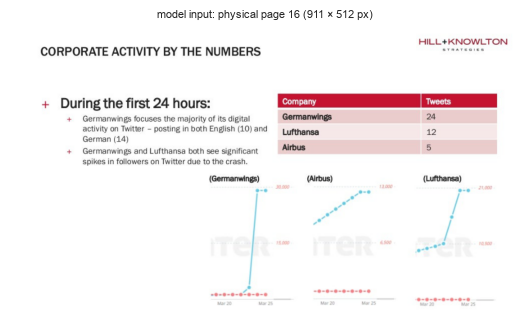

text condition, page 16: hill+knowlton corporate activity by the numbers roane nee + during the first 24 hours: + germanwings focuses the majority of its digital germanwings 24 activity on twitter - posting in both english (10) and lufthansa 42 german (14) + germanwings and lufthansa both see significant airbus 5 spikes in 


**mmlb-0033** · `earlybird-110722143746-phpapp02_95.pdf` · format `Int` · sources ['Chart', 'Table']

**Question:** How many more millions of dollars was the median exit valuation in the USA compared to Europe at the time of the presentation?

**Reference:** `63` · **evidence pages:** [6]

- **A. text, retrieved:** `63` (score 1.00) · cited [6] · supplied [6, 27, 2, 26, 30]

- **B. images, retrieved:** `64` (score 0.00) · cited [6] · supplied [6, 27, 2, 26, 30]

- **C. text, oracle:** `63` (score 1.00) · cited [6] · supplied [6, 27, 2, 26, 30]

- **D. images, oracle:** `64` (score 0.00) · cited [6] · supplied [6, 27, 2, 26, 30]

**Manual review:** visual reading — Image answer 64 instead of 63 = $236M − $173M: the two values sit in a small highlighted table at 683 x 512 px; the OCR text carried both numbers and the text model was right.

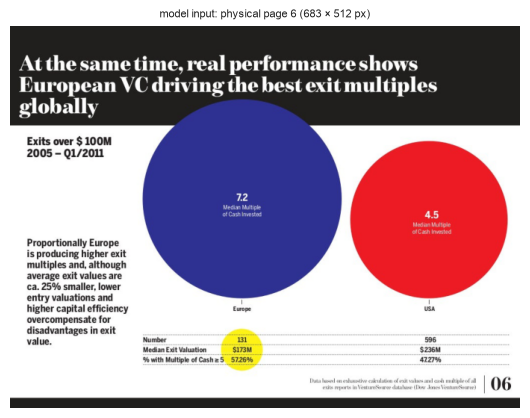

text condition, page 6: at the same time,e real performancegg shows european vca | drivingee the best exito multiplese globally exits over $ 100m 2005 - q1/2011 7.2 median multiple of cash invested 45 median multiple of cash invested proportionally europe is producing higher exit multiples and, although average exit values


In [16]:
def show_case(qid, max_pages=2):
    # Question, reference and every prediction; then the evidence pages as the image model saw them, with the text the text model got.
    row = reference.loc[qid]
    lines = [f"**{qid}** · `{row['doc_id']}` · format `{row['answer_format']}` · sources {row['evidence_sources']}",
             f"**Question:** {row['question']}", f"**Reference:** `{row['answer']}` · **evidence pages:** {row['evidence_pages']}"]
    for name in "ABCD":
        match = scored[name][scored[name]["qid"] == qid]
        if len(match):
            r = match.iloc[0]
            lines.append(f"- **{LABELS[name]}:** `{r['pred']}` (score {r['score']:.2f}) · cited {r['cited_pages']} · supplied {r['supplied_pages']}")
    if qid in MANUAL_REVIEW:
        lines.append(f"**Manual review:** {MANUAL_REVIEW[qid][0]} — {MANUAL_REVIEW[qid][1]}")
    display(Markdown("\n\n".join(lines)))
    shown = list(row["evidence_pages"])[:max_pages]
    fig, axes = plt.subplots(1, len(shown), figsize=(5.4 * len(shown), 4.6), squeeze=False)
    for ax, page_number in zip(axes[0], shown):
        pixmap = pymupdf.Pixmap(model_png(row["doc_id"], page_number))
        ax.imshow(np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.height, pixmap.width, pixmap.n))
        ax.set_title(f"model input: physical page {page_number} ({pixmap.width} × {pixmap.height} px)", fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    for page_number in shown:
        print(f"text condition, page {page_number}: {normalize_text(page_lookup.loc[(row['doc_id'], page_number), 'text'])[:300]}")


# One fix by images (an OCR digit error) and one break (a small table at slide resolution), chosen from the manual review.
for qid in ("mmlb-0729", "mmlb-0033"):
    show_case(qid)

## 9. Cost and tokens

Tokens are the `usage` the API returned for each reply; cost uses the assumed list prices. Image replies served from the response cache in the original run were paid once (when first sent), so "live cost" is what the run actually spent.

In [17]:
def usage(name):
    frame = pd.DataFrame([r for r in records[name] if r["status"] in ("ok", "parse_error")])
    source = frame["source"] if "source" in frame else pd.Series(None, index=frame.index, dtype=object)
    live = frame[source.fillna("live") == "live"]  # the text runs had no cache and predate the 'source' field: all live
    cost = lambda f: (f["prompt_tokens"].sum() * PRICES["input"] + f["completion_tokens"].sum() * PRICES["output"]) / 1e6
    return {"replies": len(frame), "live / cached replies": f"{len(live)} / {len(frame) - len(live)}",
            "prompt tokens per reply (median)": int(frame["prompt_tokens"].median()), "prompt tokens (total)": int(frame["prompt_tokens"].sum()),
            "completion tokens (total)": int(frame["completion_tokens"].sum()), "cost of all replies (USD)": round(cost(frame), 4),
            "live cost (USD)": round(cost(live), 4), "accuracy on answerable": round(answerable(scored[name])["score"].mean(), 3)}


cost_table = pd.DataFrame({LABELS[n]: usage(n) for n in "ABCD"})
ratio = cost_table.loc["prompt tokens (total)", LABELS["B"]] / cost_table.loc["prompt tokens (total)", LABELS["A"]]
print(f"Images use {ratio:.1f}× the prompt tokens of text on the same 57 questions and pages.")
cost_table

Images use 37.5× the prompt tokens of text on the same 57 questions and pages.


,"A. text, retrieved","B. images, retrieved","C. text, oracle","D. images, oracle"
replies,57,57,40,38
live / cached replies,57 / 0,52 / 5,40 / 0,13 / 25
prompt tokens per reply (median),1484,71035,1510,71036
prompt tokens (total),107988,4049223,73170,2699537
completion tokens (total),1191,1254,903,846
cost of all replies (USD),0.0169,0.6081,0.0115,0.4054
live cost (USD),0.0169,0.5548,0.0115,0.1387
accuracy on answerable,0.175,0.175,0.225,0.289


## 10. Hypotheses

In [18]:
def hypothesis_status(name, statement, by_evidence=False):
    # Observed direction only: 40 clustered questions cannot confirm a hypothesis.
    paired = PAIRED[name]
    if by_evidence:
        gains = paired.groupby("evidence_group")["score_diff"].mean()
        difference = gains.get("chart or figure", np.nan) - gains.get("text, layout or table only", np.nan)
        evidence = f"gain chart/figure {gains.get('chart or figure', np.nan):+.3f} vs text-only {gains.get('text, layout or table only', np.nan):+.3f}"
    else:
        s = paired_summary(paired)
        difference = s["difference B − A"]
        evidence = (f"{s['accuracy A']:.3f} → {s['accuracy B']:.3f}; fixed {s['fixed (A wrong → B right)']}, broken {s['broken (A right → B wrong)']}; "
                    f"McNemar p {s['exact McNemar p (ignores clustering)']:.2f}; documents better/worse/equal {s['documents better / worse / equal']}")
    status = "direction consistent (exploratory)" if difference > 0 else "direction NOT consistent" if difference < 0 else "no difference observed"
    return {"hypothesis": statement, "evidence": evidence, "status": status}


hypotheses = pd.DataFrame([
    hypothesis_status("1. retrieved pages: text → images (answerable)", "H1: images > text on the same retrieved pages"),
    hypothesis_status("1. retrieved pages: text → images (answerable)", "H2: image gain larger on chart/figure than on text-only questions", by_evidence=True),
    hypothesis_status("2. oracle pages: text → images", "H3: images > text on the oracle pages"),
])
with pd.option_context("display.max_colwidth", 150):
    display(hypotheses)

,hypothesis,evidence,status
0,H1: images > text on the same retrieved pages,"0.175 → 0.175; fixed 3, broken 3; McNemar p 1.00; documents better/worse/equal 1 / 3 / 2",no difference observed
1,H2: image gain larger on chart/figure than on text-only questions,gain chart/figure +0.000 vs text-only +0.000,no difference observed
2,H3: images > text on the oracle pages,"0.237 → 0.289; fixed 6, broken 4; McNemar p 0.75; documents better/worse/equal 2 / 3 / 1",direction consistent (exploratory)


## Validation

In [19]:
# 1. Denominators: each condition covers its population minus protocol skips (D only), with no failed call.
assert len(A) == len(B) == 57 and len(C) == 40 and len(D) == 38 and set(D["qid"]) <= set(C["qid"])
assert all(frame["status"].isin(["ok", "parse_error"]).all() for frame in scored.values())
# 2. Paired comparisons are paired: identical question sets on both sides, one row per question.
for name, (a, b) in COMPARISONS.items():
    assert set(PAIRED[name]["qid"]) == set(a["qid"]) == set(b["qid"]) and PAIRED[name]["qid"].is_unique, name
# 3. A and B (and C and D) received exactly the same pages.
for x, y in (("A", "B"), ("C", "D")):
    pages_x = {r["qid"]: r["supplied_pages"] for r in records[x]}
    assert all(pages_x[r["qid"]] == r["supplied_pages"] for r in records[y]), (x, y)
# 4. Scores are in [0, 1] and 'correct' is exactly score > 0.
assert all(frame["score"].between(0, 1).all() and (frame["correct"] == (frame["score"] > 0)).all() for frame in scored.values())
# 5. Manual review: all 28 queued questions labelled, 29 cases in total, each with a known category.
assert (queue["manual_label"] != "pending").all() and set(queue["qid"]) <= set(MANUAL_REVIEW) and len(MANUAL_REVIEW) == 29

evaluation_summary = {
    "predictions": prediction_manifest,
    "metrics": {LABELS.get(n, n): {k: (None if isinstance(v, float) and np.isnan(v) else v) for k, v in condition_metrics(f).items()} for n, f in scored.items()},
    "paired": {name: paired_summary(p) for name, p in PAIRED.items()},
    "manual_review": MANUAL_REVIEW,
}
(PROCESSED_DIR / "evaluation_summary.json").write_text(json.dumps(evaluation_summary, indent=2, default=lambda v: v.item() if hasattr(v, "item") else str(v)))
assert len(json.loads((PROCESSED_DIR / "evaluation_summary.json").read_text())["manual_review"]) == 29
print("All validation checks passed. Summary saved to", (PROCESSED_DIR / "evaluation_summary.json").relative_to(PROJECT_ROOT))

All validation checks passed. Summary saved to data/processed/mmlongbench_doc/evaluation_summary.json


## Results and interpretation

*6 MMLongBench-Doc documents, 57 questions (40 answerable), gpt-4o-mini-2024-07-18, temperature 0, one run per condition; local rule-based scoring.*

| | A text, retrieved | B images, retrieved | C text, oracle | D images, oracle |
|---|---|---|---|---|
| correct, answerable | 7/40 (0.175) | 7/40 (0.175) | 9/40 (0.225); 9/38 (0.237) | 11/38 (0.289) |
| accuracy, all 57 / F1 | 0.263 / 0.165 | 0.228 / 0.156 | — | — |
| correct abstention (17 unanswerable) | 8/17 | 6/17 | — | — |
| citation validity | 1.000 | 0.895 | 1.000 | 0.921 |
| prompt tokens per question (mean) | ≈ 1.9k | ≈ 71k | ≈ 1.8k | ≈ 71k |

**Findings**

1. **Text reading, not retrieval, limits the text pipeline.** BM25 puts an evidence page in the top 5 for 32 of 40 questions (Hit@5 0.800), yet only 7 are answered correctly; giving the text model the evidence fixes 2.
2. **Images do not raise accuracy on the retrieved pages; they trade errors** (3 fixed, 3 broken, McNemar p = 1.00, 1 of 6 documents better). The fixes are in image-only slide decks where OCR misread or missed what the 512-px image shows (`mmlb-0729`: OCR read "42" for "12"); the breaks lose small detail (`mmlb-0033`, a small table; `mmlb-0313`, outlined text nearly illegible at 60 dpi; `mmlb-0096`, an irrelevant page cited).
3. **Images make the model answer more often, in both directions:** false abstentions fall from 4/40 to 1/40, but correct abstentions also fall from 8/17 to 6/17, so all-question accuracy and F1 drop slightly.
4. **A new citation failure.** Image replies cite pages that were not supplied (6 in B, 3 in D, none for text). In 7 of these 9 replies every invalid page is exactly one below a supplied page, consistent with citing the page number printed on the page.
5. **The image reader benefits more from correct pages** (4 fixed, 0 broken from retrieved to oracle, all on BM25 misses) than the text reader (2 fixed).
6. **Some errors are annotation or scoring artefacts** (4 of the 29 reviewed cases, below): a correct sentence-length answer scores 0 under the `Str` rule (`mmlb-0034`), two references cannot be scored under their declared `Int` format (`mmlb-0733`, `mmlb-0735`), and one reference is taken from a small caption ("Hour 3") rather than the slide text ("within the first 4 hours", `mmlb-0736`).

**Manual error review (29 cases).** One primary label per case for all 28 questions in the comparison-1 review queue (0 pending) and for `mmlb-0313`, a break outside the queue.

| primary label | queued (28) | all reviewed (29) |
|---|---|---|
| reasoning or aggregation | 11 | 11 |
| visual reading | 8 | 9 |
| annotation or scoring issue | 4 | 4 |
| text representation | 3 | 3 |
| retrieval | 2 | 2 |
| citation, abstention | 0 | 0 |

- **Most queued failures do not depend on the representation.** 23 queued questions are wrong for both readers (11 reasoning, 6 visual reading, 4 annotation, 2 retrieval), and 22 of them stay wrong in every oracle reply; only `mmlb-0359` is fixed (by text, on oracle pages). The reasoning failures are counts over a page or figure (`mmlb-0094`, `mmlb-0763`, `mmlb-0766`), differences of combined percentages (`mmlb-0360`, `mmlb-0362`, `mmlb-0363`), and a headline or title value taken instead of the chart (`mmlb-0355`, `mmlb-0041`).
- **Where the readers disagree, the labels match the mechanical diagnostic.** The 3 image fixes are text-representation failures: an OCR digit error (`mmlb-0729`) and two counts of visual items that the extracted text does not preserve (`mmlb-0732`, `mmlb-0739`; the mechanical check found the answer digit in the text, but not a countable structure). The 2 breaks (`mmlb-0033`, `mmlb-0096`) and `mmlb-0313` are visual-reading failures.
- **Visual reading fails on small detail at ≈ 60 dpi:** digits in small tables or infographics (`mmlb-0033`, `mmlb-0737`), labels and arrows in drawings (`mmlb-0095`, `mmlb-0315`, `mmlb-0317`), a ~12-px logo (`mmlb-0731`) and outlined text (`mmlb-0313`).
- **Retrieval is primary in only 2 cases** (`mmlb-0035`, `mmlb-0359`) because the queue requires some evidence in the top 5; of the 8 comparison-1 questions with none, only `mmlb-0313` was reviewed.

*Primary versus secondary.* The counts use primary labels only. Secondary factors are recorded in the explanations: partial retrieval misses where the oracle condition also failed (`mmlb-0362`, `mmlb-0762`, `mmlb-0765`, `mmlb-0766`, all labelled reasoning); an aggregation failure behind a retrieval miss (`mmlb-0035`, text oracle also wrong); small print (`mmlb-0733`, `mmlb-0763`); a scoring artefact (`mmlb-0041`, "300 million" would reject 300); and a citation of an unsupplied page (`mmlb-0317`). Citation and abstention errors occur, but are never primary.

*Uncertainty.* Five labels rest on evidence not fully verified: the reference of `mmlb-0318` (100 mm) still needs checking on the original high-resolution PDF; the reference counts of `mmlb-0762` and `mmlb-0763` were not independently verified on the low-resolution renders; `mmlb-0766` is ambiguous between figures and subplots; and `mmlb-0769` is a qualitative judgement, as the figure gives no variance values. A wrong reference would move a case to "annotation or scoring issue".

*Scope.* The cases were selected by the queue, not sampled, so these counts describe the reviewed selection, not error rates of the benchmark or of either reader.

**Hypotheses.** H1 (images > text on retrieved pages): **not supported** (0.175 = 0.175). H2 (larger image gain on chart/figure questions): **not supported**; the pattern follows the *document* (slide decks gain, low-resolution documents lose), which is confounded with evidence type and legibility. H3 (images > text on oracle pages): **direction consistent, not established** (+2 questions net, 6 fixed / 4 broken, p = 0.75).

**Synthesis.** With gpt-4o-mini and the ≈ 60-dpi images its token cost allows, swapping extracted text for page images changes *which* questions are answered rather than *how many*, at ≈ 37× the input tokens. Every statement rests on 38–57 questions in 6 documents and is a hypothesis to test, not a result to generalise.

## Limitations

- **Small, clustered sample:** one question moves answerable accuracy by 0.025; McNemar p-values are optimistic; every subgroup result is exploratory.
- **Resolution set by cost:** the comparison is "text versus 512-px page images" (legibility proxy 0.05–0.06 on two documents).
- **Local scoring:** structured JSON answers replace the official GPT-4o extraction stage; scores are not leaderboard-comparable. Parity rests on hand-traced cases. 4 of 1,091 references can never score 1.0 (two in this subset: `mmlb-0733`, `mmlb-0735`).
- **One run per condition:** at temperature 0, 3–6 of 57 text predictions changed between identical runs (no score changed so far). Image run-to-run variation is unmeasured.
- **Citation validity is vacuous for empty citations** (abstentions cite `[]`): read it together with abstention counts.
- **Manual review covers a selection:** 29 queued or notable cases, one primary label each, no inter-annotator agreement measured; five labels rest on evidence not fully verified.

## Failure case to remember

`mmlb-0041`: the slide title says "exit values at around $350M"; both readers copied 350 while the chart shows about 300, and even 300 would score 0 against the reference string "300 million". A single wrong answer can mix a distractor, a reading error and a scoring artefact, which is why aggregate accuracy alone cannot explain the system.

## Next steps

1. Address the printed-page citation failure (state in the image prompt that printed page numbers are not the `[Page N]` tags, or stamp the tag into the image) as a **new condition**, compared with B.
2. Verify the uncertain references (`mmlb-0318`, `mmlb-0762`, `mmlb-0763`, `mmlb-0766`) on the original PDFs with `show_case(qid)`, and relabel a case if its reference is wrong; the scores and scoring rules stay as frozen.
3. Separate representation from resolution: repeat A–D with a model whose image tokens allow the default 768-px input, or test text + image together.
4. Measure image run-to-run variation (re-run B with the cache off, ≈ $0.56), then enlarge the sample (more documents or seeds).